# XOR Contest

## 1. What is XOR?

XOR ("exclusive or") outputs 1 when **exactly one** of its inputs is 1:

| x₁ | x₂ | XOR |
|----|----|-----|
| 0  | 0  | 0   |
| 0  | 1  | 1   |
| 1  | 0  | 1   |
| 1  | 1  | 0   |

The whole dataset is these 4 points.
There is no test set and no generalization question.

The question is whether a single-layer/single-neuron model network (with a monotonic activation function) can **fit** these four points, and how quickly.

Goal: 

* Design a neural network to solve the XOR problem
* Ablation experiments
* Discuss the results


Reference:
* [how-neural-networks-solve-the-xor-problem/](https://www.geeksforgeeks.org/artificial-intelligence/how-neural-networks-solve-the-xor-problem/)


## 2. Why a single neuron cannot do it

A single neuron (perceptron) computes

$$\hat y = f(w_1 x_1 + w_2 x_2 + b)$$

Its decision boundary, $w_1x_1 + w_2x_2 + b = 0$, is a **straight line**. It can only solve problems where one line separates the classes, i.e. **linearly separable** problems.

The 1s sit on one diagonal and the 0s on the other. **No single straight line separates them.**

As it is possible to see in the graph below, this is not separable.

In [1]:
# imports

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

import plotly.io as pio

REPORT = True   # set to True, then "Run All", right before exporting the PDF

pio.renderers.default = "png" if REPORT else "vscode"
pio.defaults.default_scale = 2      # sharp PNGs in the PDF

# Report layout: wrap long code/output lines and shrink tables so they fit the PDF page width
REPORT_CSS = """<style>
.jp-OutputArea-output table { font-size: 10px; table-layout: auto; width: 100%; }
.jp-OutputArea-output th, .jp-OutputArea-output td { padding: 2px 4px; word-break: break-word; }
.jp-OutputArea-output img { max-width: 100%; height: auto; }
.jp-OutputArea-output pre, .jp-InputArea-editor pre, .highlight pre { white-space: pre-wrap; word-break: break-word; }
.jp-OutputArea-output pre { font-size: 10px; }
</style>"""
if REPORT:
    from IPython.display import HTML, display
    display(HTML(REPORT_CSS))


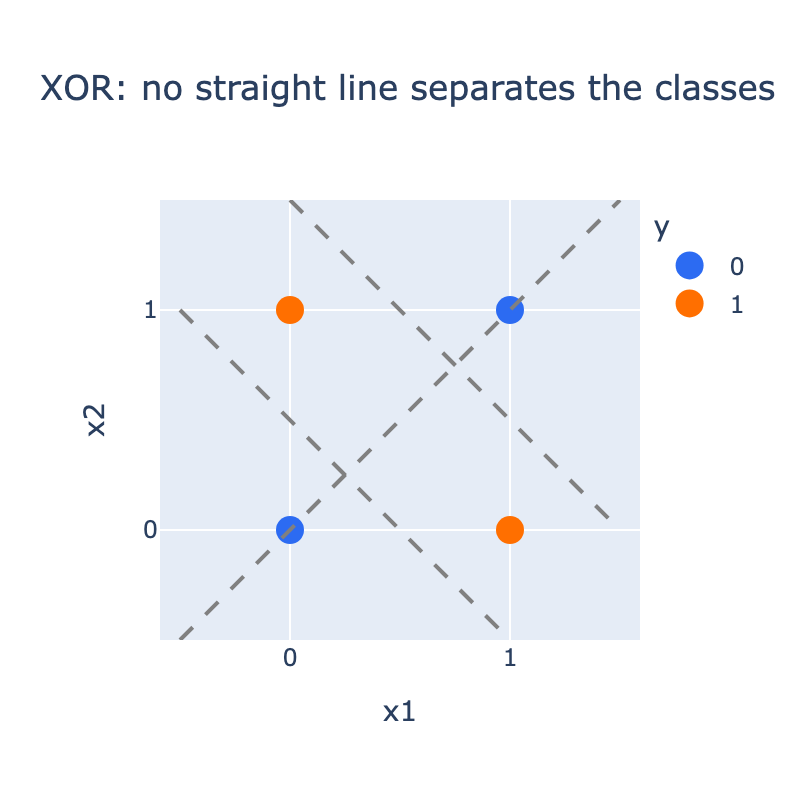

In [2]:
# xor points position and results
df = pd.DataFrame({"x1": [1, 0, 1, 0],
                   "x2": [1, 0, 0, 1],
                   "y":  ["0", "0", "1", "1"]})

# XOR visualization
colors = {"0": "#2c6bf2", "1": "#ff6f00"}

fig = px.scatter(df,
                 x = "x1",
                 y = "x2",
                 color="y",
                color_discrete_map = colors,
                width=400,
                height=400,
                title="XOR: no straight line separates the classes",
    )

fig.update_traces(marker_size=14,
                  textposition="top center")

# Change visualization range
fig.update_xaxes(range=[-0.5, 1.5], dtick=1)
fig.update_yaxes(range=[-0.5, 1.5], dtick=1, scaleanchor="x")   # square axes

# Remove thicker 0 lines
fig.update_xaxes(zeroline=False)
fig.update_yaxes(zeroline=False)

# Three attempts at a separating line: each leaves points on the wrong side
for x0, y0, x1, y1 in [(-0.5, 1, 1, -0.5),    # x1 + x2 = 0.5
                       (0, 1.5, 1.5, 0),       # x1 + x2 = 1.5
                       (-0.5, -0.5, 1.5, 1.5)]:  # x2 = x1
    fig.add_shape(type="line", x0=x0, y0=y0, x1=x1, y1=y1,
                  line=dict(dash="dash", color="gray"))
    
fig.show()

Additional thoughts: 

Activation functions introduce non-linearities to the model, however, the monotonic condition constrains our ability to solve this in one layer and one neuron. 

Applying a activation function that is monotonic (ReLu, sigmoid, Tanh, etc.), as required, is not able to fit a data that goes low then high as the XOR problem, only a non-monotonic function as the abs(x).   

# 3. Designing the Network

Considering the issue with the separability, we need to find a representation in which the data becomes
linearly separable. We do that by adding a **hidden layer** to the model.

A hidden layer maps the input into a new feature space, and its **number of neurons sets the dimension**
of that space: each neuron computes one new feature (one new coordinate). One hidden neuron gives a 1D
representation, two hidden neurons give a 2D one, and so on. In this new space, we
may now separate the classes, so we need **at least one hidden layer**.

We can visualize this idea below by adding one hand-made feature, $x_1 \cdot x_2$ (the AND gate, which
is itself linearly separable). Together with $x_1$ and $x_2$ it gives a 3D space where a plane separates
the two classes:


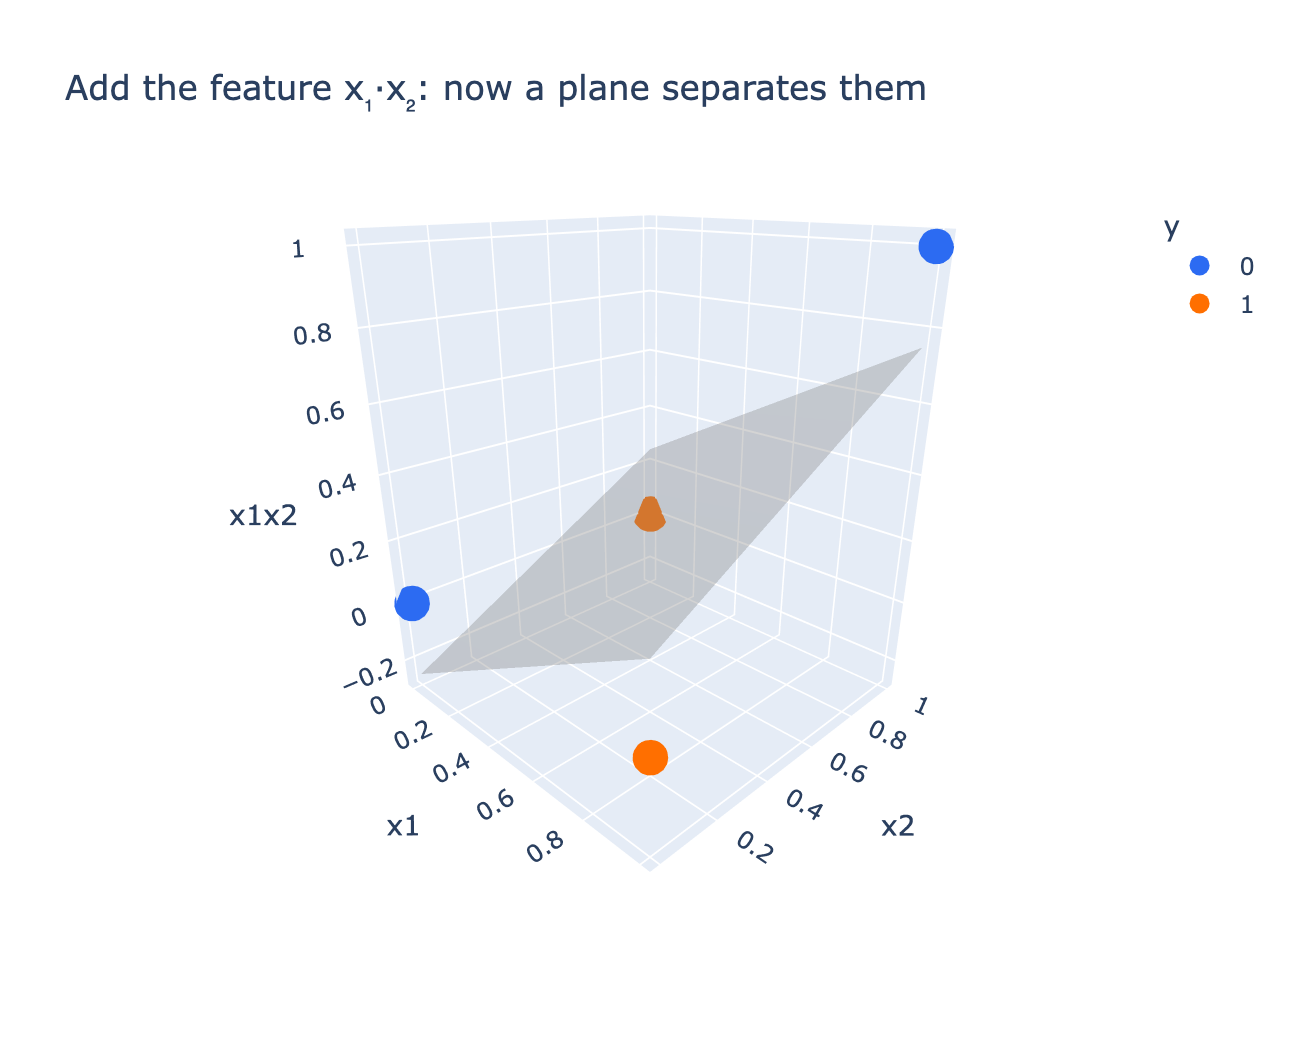

In [3]:
df["x1x2"] = df["x1"] * df["x2"] # The AND gate (which is separable)

fig3 = px.scatter_3d(df, x="x1", y="x2", z="x1x2", color="y",
                     color_discrete_map=colors, width=500, height=500,
                     title="Add the feature x₁·x₂: now a plane separates them")
fig3.update_traces(marker_size=10)

# Fix the camera angle for the report later
def camera(azimuth=45, elevation=25, distance=2.0):
    """azimuth: rotation around the vertical axis (degrees), elevation: height above the floor (degrees)."""
    az, el = np.radians(azimuth), np.radians(elevation)
    return dict(eye=dict(x=distance * np.cos(el) * np.cos(az),
                         y=distance * np.cos(el) * np.sin(az),
                         z=distance * np.sin(el)),
                center=dict(x=0, y=0, z=-0.15))   # keeps your "move the box up" fix

fig3.update_layout(scene_camera=camera(azimuth=-45, elevation=20, distance=2.0))

g = np.linspace(0, 1, 10)
xx, yy = np.meshgrid(g, g)

fig3.add_trace(go.Surface(x=xx, y=yy, z=(xx + yy - 0.5) / 2,   # separating plane
                          opacity=0.35, showscale=False,
                          colorscale=[[0, "gray"], [1, "gray"]]))

fig3.show(width=650, height=520)



### Why at least 2 hidden neurons are required to solve XOR

To understand why a single hidden neuron fails while two succeed, we need to look at how monotonic activations interact with spatial geometry.

1. **Monotonicity Preserves Topological Order:**
A monotonic activation function $f(z)$ is order-preserving ($a \ge b \implies f(a) \ge f(b)$). It can stretch, squash, or shift values, but it cannot fold a dimension back on itself or invert the relative ordering of points along a line.

2. **Why 1 Hidden Neuron Fails ($N_h = 1$):**
A single neuron computes $h(\mathbf{x}) = f(\mathbf{w}^T \mathbf{x} + b)$, projecting the 2D input down to a 1D scalar line ($\mathbb{R}^2 \to \mathbb{R}^1$).
In the original 2D space, the line connecting Class 0 points $(0,0)$ and $(1,1)$ intersects the line connecting Class 1 points $(0,1)$ and $(1,0)$. Any 1D projection forces these points to land in an interleaved (sandwiched) order along that axis. Because a monotonic function preserves this relative ordering, it cannot untangle the interleaved points into a linearly separable 1D representation.
3. **Why 2 Hidden Neurons Succeed ($N_h = 2$):**
To disentangle the points, we must map them into a new space without collapsing them into 1D. Two hidden units provide two linearly independent weight vectors, $\mathbf{w}_1$ and $\mathbf{w}_2$, which act as a new 2D basis ($\mathbb{R}^2 \to \mathbb{R}^2$).
This hidden layer transformation maps the data into a new 2D coordinate system $(h_1, h_2)$ where the opposite classes no longer overlap. Once this linearly separable representation is constructed, the final layer ($N_{\text{out}} = 1$) can project the $\mathbb{R}^2$ hidden features down to a 1D output ($\mathbb{R}^2 \to \mathbb{R}^1$) by drawing a single linear decision boundary across the space.


### Chosen architecture (baseline)

**Fixed by the assignment**
* Input: 2 neurons ($N_{\text{in}} = 2$)
* Output: 1 neuron ($N_{\text{out}} = 1$)

**Design choices**
* **Output activation: sigmoid.** Output in $(0,1)$, matching the 0/1 targets, and read as $P(y=1)$
  (class = 1 if $\hat y > 0.5$).
* **Hidden layers:** 1 hidden layer with $N_h = 2$ neurons, the theoretical minimum:
  XOR = AND(OR, NAND) needs two linear decision boundaries.
* **Hidden activation: tanh.** Output in $(-1,1)$, zero-centred, and its derivative peaks at 1
  (sigmoid's peaks at 0.25), so gradients are larger and learning is usually faster.
* **Weight initialization: Glorot normal** (set explicitly; the Keras default is Glorot uniform).
  Random, to break the symmetry between neurons, and scaled for tanh/sigmoid.
* **Loss: binary cross-entropy.** Chosen *together with* the sigmoid output since this loss is only appropriate when the output are binary probabilities.
* **Optimizer: SGD** (plain, no momentum), learning rate $\eta = 0.5$.
* **Training:** full batch (`batch_size=4`), so 1 epoch = 1 weight update.



### Convergence criterion and reproducibility

**When is the error "minimized"?** With a sigmoid output, the loss keeps shrinking forever (the output never reaches exactly 0 or 1). So "the epoch where the error is minimized" only exists once we define a threshold:

> **Converged** = the mean squared error between the predictions and the targets drops below **0.01** (predictions on average within ~0.1 of the targets).

* The MSE is tracked as a **metric** in every run, whatever loss is used for training. That lets us compare runs with different cost functions (BCE vs MSE) and output layers (sigmoid vs linear) on the same scale.
* Training **stops at the first converged epoch**. That epoch is the score: fewer is better.
* A run that stops improving (loss improves by less than 1e-5 within 200 epochs) is stopped as **stuck**. A run that hits the epoch limit (2000) counts as **not converged**.
* There is **no validation set**: the 4 points are the entire input space. The question is how fast the network *fits* them, not how well it generalizes.

**Reproducibility:**
* Every run sets the same random seed (`seed = 3`) before building the model, so every configuration starts from the same random state.
* TensorFlow's deterministic mode is enabled, so re-running the notebook gives identical numbers.
* Library versions are printed below.
* Every run (configuration, metrics, full training curve) is saved to `results/`.
* All experiments use **one seed**. That keeps things simple, but some outcomes (especially "stuck" runs) can depend on the seed.


In [4]:

# setup and reproducibility
import os, json, platform
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow info messages
import tensorflow as tf
import keras
from time import perf_counter
import matplotlib.pyplot as plt

tf.config.experimental.enable_op_determinism()      # same seed -> identical results on every re-run

print(f"Python {platform.python_version()} | TensorFlow {tf.__version__} | "
      f"Keras {keras.__version__} | NumPy {np.__version__}")

# Input: the whole XOR input space
x = np.array([(1,1), (0,0), (1,0), (0,1)], dtype="float32")
y = np.array([0, 0, 1, 1], dtype="float32").reshape(-1, 1)
input_dim = x.shape[-1]

MSE_THRESHOLD = 0.01      # converged = MSE between predictions and targets below this value

base_config = dict(
    # hyperparameters
    lr = 0.5,
    optimizer = "sgd",      # "sgd" or "adam"
    momentum = 0.0,         # only used by SGD
    epochs = 2000,          # upper limit; training stops earlier once converged
    batch_size = len(x),    # full batch: 1 epoch = 1 weight update
    seed = 3,
    patience = 200,         # stop a stuck run after 200 epochs without improvement
    # model
    n_h = 2,                # int = one hidden layer with n_h neurons; list, e.g. [8, 8] = several hidden layers
    activation_h = "tanh",
    activation_out = "sigmoid",
    init = "glorot_normal", # https://keras.io/api/layers/initializers/
    loss = "binary_crossentropy",
)


Python 3.11.13 | TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.4.6


In [5]:

class StopWhenConverged(keras.callbacks.Callback):
    """Stops training at the first epoch where the MSE drops below the threshold."""
    def __init__(self, threshold):
        super().__init__()
        self.threshold = threshold
        self.converged_at = None

    def on_epoch_end(self, epoch, logs=None):
        if logs["mse"] < self.threshold:
            self.converged_at = epoch + 1
            self.model.stop_training = True


def make_optimizer(config):
    if config["optimizer"] == "sgd":
        return keras.optimizers.SGD(config["lr"], momentum=config["momentum"])
    if config["optimizer"] == "adam":
        return keras.optimizers.Adam(config["lr"])
    raise ValueError(f"unknown optimizer {config['optimizer']}")


def train(config):
    # 1. makes the run reproducible
    keras.utils.set_random_seed(config["seed"])

    # 2. Create the Model 
    hidden = config["n_h"] if isinstance(config["n_h"], list) else [config["n_h"]] # when is int transform in a list
    layers = [keras.layers.Input((input_dim,))]

    # 2.1 Hidden layers
    for units in hidden:
        layers.append(keras.layers.Dense(units, activation=config["activation_h"],
                                         kernel_initializer=keras.initializers.get(config["init"])))

    # 2.2 Last layer 
    layers.append(keras.layers.Dense(1, activation=config["activation_out"],
                                     kernel_initializer=keras.initializers.get(config["init"])))
    model = keras.Sequential(layers)

    # 3. Compile: "mse" is tracked for every run, whatever the training loss is
    model.compile(
        optimizer=make_optimizer(config),
        loss=config["loss"],
        metrics=["mse", keras.metrics.BinaryAccuracy(threshold=0.5, name="accuracy")], # split set the threshold of the accuracy just for my personal learning process
    )

    # 4. Callbacks
    # success: stop as soon as the error is below the threshold
    converged = StopWhenConverged(MSE_THRESHOLD)
    # failure: give up on runs stuck on a plateau / local minimum
    stuck = keras.callbacks.EarlyStopping(monitor="loss", patience=config["patience"], min_delta=1e-5)
    # Note: an absolute change of less than min_delta, will count as no improvement. Defaults to 0.
    # https://keras.io/api/callbacks/early_stopping/ 

    # 5. Train (there is no validation data) + timing the run
    t0 = perf_counter()
    history = model.fit(
        x = x,
        y = y,
        epochs = config["epochs"],
        batch_size = config["batch_size"],
        callbacks=[converged, stuck],
        verbose=0,
    )
    t1 = perf_counter()

    return {"model": model, "history": history, "elapsed": t1 - t0,
            "converged_at": converged.converged_at}



### Saving and comparing results

Every experiment goes through `run(experiment, name, **changes)`:

* It copies `base_config` and applies only the `changes`, so each run is the baseline plus the listed differences.
* It trains, then stores the configuration, the result and the full training curve in `RUNS`.
* It saves everything to `results/runs.json` (complete) and `results/summary.csv` (the table).

`show(experiment)` prints the comparison table (with the baseline as reference) and plots the error curves.


In [6]:
import plotly.express as px

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
RUNS = []        # one dict per run: experiment, name, changes, config, results, curves


def run(experiment, name, **changes):
    config = {**base_config, **changes}
    out = train(config)
    history = out["history"].history
    epochs_run = len(history["loss"])

    if out["converged_at"]:
        status = "converged"
    elif epochs_run < config["epochs"]:
        status = "stuck"
    else:
        status = "not converged"

    record = dict(
        experiment=experiment,
        name=name,
        changes=", ".join(f"{k}={v}" for k, v in changes.items()) or "-",
        epochs_to_converge=out["converged_at"],
        status=status,
        epochs_run=epochs_run,
        final_mse=history["mse"][-1],
        final_accuracy=history["accuracy"][-1],
        time_s=out["elapsed"],
        predictions=[round(float(v), 3) for v in np.asarray(out["model"](x, training=False)).ravel()],
        config=config,
        curves={"loss": history["loss"], "mse": history["mse"]},
    )
    # re-running a cell replaces the old result instead of duplicating it
    RUNS[:] = [r for r in RUNS if (r["experiment"], r["name"]) != (experiment, name)]
    RUNS.append(record)
    save_results()
    print(f"{name:40s} {status:14s} epochs: {out['converged_at'] or '-':>5}  ({out['elapsed']:.1f}s)")
    return record


def summary_table(runs):
    base = next((r["epochs_to_converge"] for r in RUNS if r["experiment"] == "baseline"), None)
    df = pd.DataFrame([{k: r[k] for k in ["experiment", "name", "changes", "epochs_to_converge", "status",
                                         "final_mse", "final_accuracy", "time_s", "predictions"]}
                       for r in runs])
    df["speedup_vs_baseline"] = [f"{base / e:.1f}x" if pd.notna(e) and base else "-" for e in df["epochs_to_converge"]]
    df["epochs_to_converge"] = df["epochs_to_converge"].astype("Int64")      # integer, shows <NA> if not converged
    df["final_mse"] = df["final_mse"].map("{:.4f}".format)
    df["time_s"] = df["time_s"].round(1)
    return df


def save_results():
    with open(f"{RESULTS_DIR}/runs.json", "w") as f:
        json.dump(RUNS, f, indent=1)
    summary_table(RUNS).to_csv(f"{RESULTS_DIR}/summary.csv", index=False)


def plot_curves(runs, title, use_log_axis = True):
    rows = [{"epoch": i + 1, "MSE": v, "run": r["name"]}
            for r in runs for i, v in enumerate(r["curves"]["mse"])]
    fig = px.line(pd.DataFrame(rows), x="epoch", y="MSE", color="run", log_y=use_log_axis,
                  width=750, height=400, title=f"{title}<br><sup>dotted line = convergence threshold</sup>")

    if use_log_axis:
        fig.update_yaxes(title_text="MSE (log scale)") # log scale
    
    fig.add_hline(y=MSE_THRESHOLD, line_dash="dot", line_color="gray")
    fig.show()


# report mode: hide some columns (still saved in results/summary.csv) and shorten the headers
REPORT_HIDE = ["predictions", "time_s", "final_accuracy"]
REPORT_HEADERS = {"epochs_to_converge": "epochs", "final_mse": "final MSE", "speedup_vs_baseline": "speedup"}

def table(df, hide=()):
    """Full table in the notebook; compact table (fewer columns, short headers) in report mode."""
    if not REPORT:
        return df
    drop = [c for c in [*REPORT_HIDE, *hide] if c in df.columns]
    return df.drop(columns=drop).rename(columns=REPORT_HEADERS)


def show(experiment, use_log_axis = True):
    runs = [r for r in RUNS if r["experiment"] in ("baseline", experiment)]
    display(table(summary_table(runs).drop(columns=["experiment"]).set_index("name")))
    plot_curves(runs, f"{experiment}: error (MSE) vs epochs", use_log_axis)


## Baseline run

baseline                                 converged      epochs:   231  (3.2s)

Predictions: [0.138, 0.099, 0.93, 0.93] targets: [0. 0. 1. 1.]

Accuracy 1.0


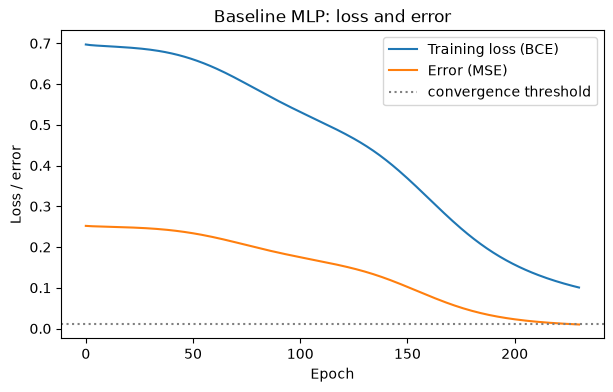

In [7]:

base_result = run("baseline", "baseline")

print("\nPredictions:", base_result["predictions"], "targets:", y.ravel())
print("\nAccuracy", base_result["final_accuracy"])

# plot
plt.figure(figsize=(7, 4))
plt.plot(base_result["curves"]["loss"], label="Training loss (BCE)")
plt.plot(base_result["curves"]["mse"], label="Error (MSE)")
plt.axhline(MSE_THRESHOLD, color="gray", ls=":", label="convergence threshold")
# plt.yscale("log") # enable log scale when needed
plt.xlabel("Epoch")
plt.ylabel("Loss / error")
plt.title("Baseline MLP: loss and error")
plt.legend()
plt.show()



**Baseline result:** the baseline converges (MSE < 0.01) after **231 epochs**, with predictions ≈ [0.14, 0.10, 0.93, 0.93] for the targets [0, 0, 1, 1] (accuracy 100%).

With a fixed number of epochs (the first version, 1000 epochs) the loss just kept getting smaller and never "finished", so this criteria was created to make it easier to compare the results. The convergence criterion turns that into a concrete number we can compare: **231 epochs is the reference that every experiment tries to beat now.**

The evaluation uses the same 4 points as training, since there is no validation set.



# Experiments

Requirements from the assignment: 
* Change the network topology, the initialization, the activation and cost functions to
achieve the lesser amount of epochs that lead to the minimization of the error.

* Discuss what options lead to the lesser amount of training epochs.

**Strategy:**
* **Experiments 1–5 change one thing at a time** from the baseline (an ablation study). Since only one setting differs, any change in epochs can be attributed to that setting.
* **Experiment 6 is cumulative**: it starts from the baseline and adds the best option of each group, step by step. Choices may interact (for example ReLU tends to need another type of initialization), so each step re-tests its options *on top of* the current best configuration instead of just stacking the individual winners.



## Experiment 1: changing the activation of the hidden layer

The baseline uses tanh. Here only the hidden activation changes; everything else stays the baseline:
* 2 hidden neurons,
* sigmoid output,
* BCE (Binary Cross-Entropy),
* SGD 0.5.


hidden sigmoid                           converged      epochs:  1540  (18.7s)
hidden relu                              converged      epochs:   185  (2.5s)
hidden leaky_relu                        converged      epochs:   308  (4.0s)
hidden elu                               stuck          epochs:     -  (4.5s)


,changes,epochs,status,final MSE,speedup
name,,,,,
baseline,-,231,converged,0.0099,1.0x
hidden sigmoid,activation_h=sigmoid,1540,converged,0.0100,0.1x
hidden relu,activation_h=relu,185,converged,0.0099,1.2x
hidden leaky_relu,activation_h=leaky_relu,308,converged,0.0098,0.8x
hidden elu,activation_h=elu,<NA>,stuck,0.2500,-


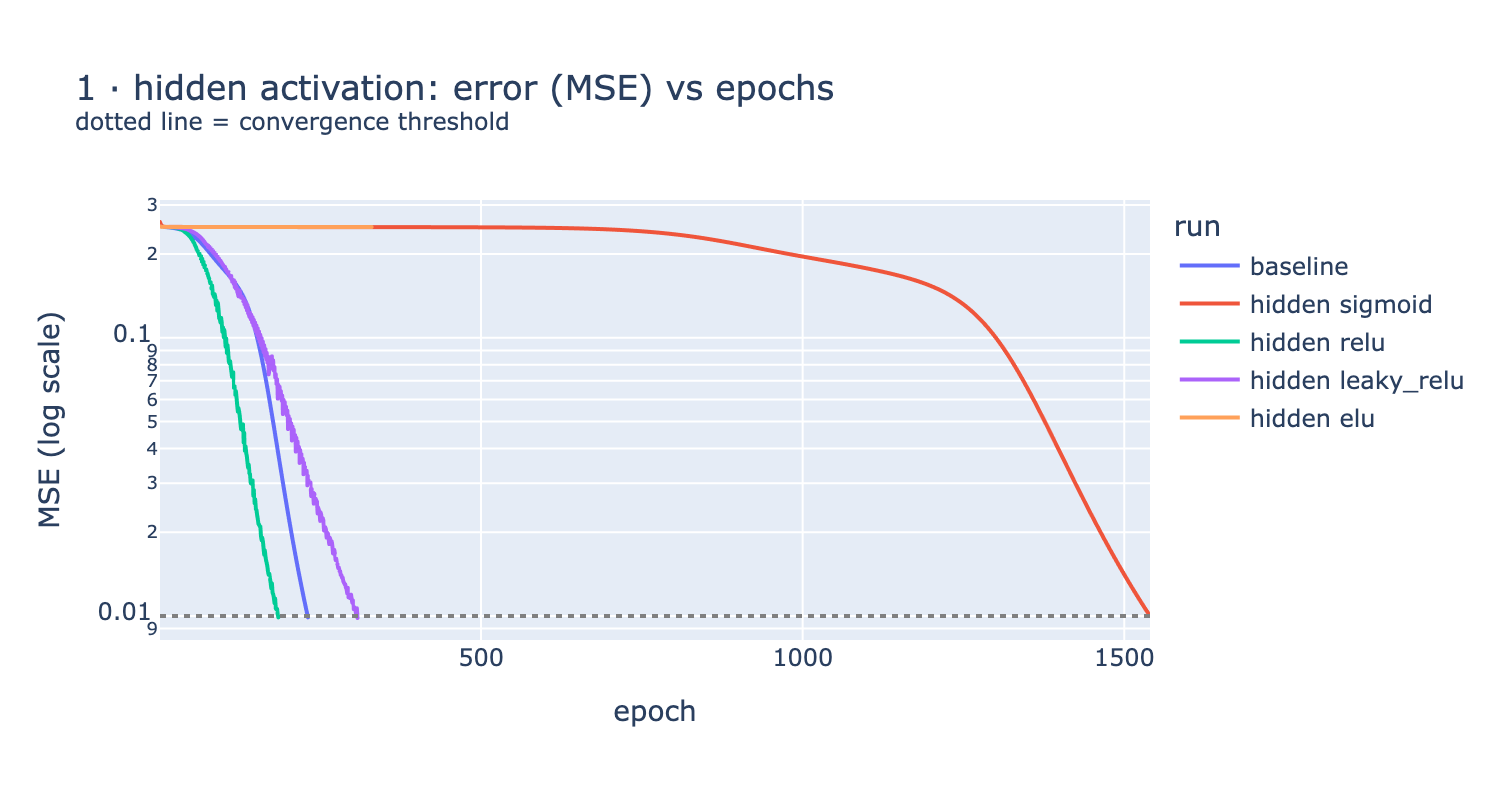

In [8]:

EXP1 = "1 · hidden activation"
for activation in ["sigmoid", "relu", "leaky_relu", "elu"]:
    run(EXP1, f"hidden {activation}", activation_h=activation)
show(EXP1)

**Results:**
* **ReLU** was the only activation faster than the baseline: it converged in 185 epochs vs 231 (1.2× speed-up).
  With only 2 hidden neurons it is risky, though: a neuron that outputs 0 for all four inputs stops learning
  ("dead ReLU"), which most likely explains why *linear output + ReLU* got stuck in Experiment 2.
* **Sigmoid was 6.7× slower** (1540 epochs). Its derivative is at most 0.25 (tanh's is 1) and its output isn't
  zero-centred, so the gradients reaching the first layer are small.
* **Leaky ReLU was slower** than the baseline (308 epochs) and **ELU got stuck** with this seed.


## Experiment 2: changing the last layer activation and loss

* **sigmoid output + MSE:** only the loss changes, which shows the effect of the cost function on its own.
* **linear output + MSE:** XOR treated as a regression problem (threshold at 0.5 afterwards).
* **linear output + MSE + ReLU hidden:** the same, with a different hidden activation.

Linear output + BCE is not tested: BCE needs outputs in (0, 1), and a linear output can be any number.


sigmoid out + MSE                        converged      epochs:   584  (7.2s)
linear out + MSE                         converged      epochs:   201  (2.6s)
linear out + MSE, relu hidden            stuck          epochs:     -  (3.3s)


,changes,epochs,status,final MSE,speedup
name,,,,,
baseline,-,231,converged,0.0099,1.0x
sigmoid out + MSE,loss=mean_squared_error,584,converged,0.0100,0.4x
linear out + MSE,"activation_out=linear, loss=mean_squared_error",201,converged,0.0100,1.1x
"linear out + MSE, relu hidden","activation_out=linear, loss=mean_squared_error...",<NA>,stuck,0.1667,-


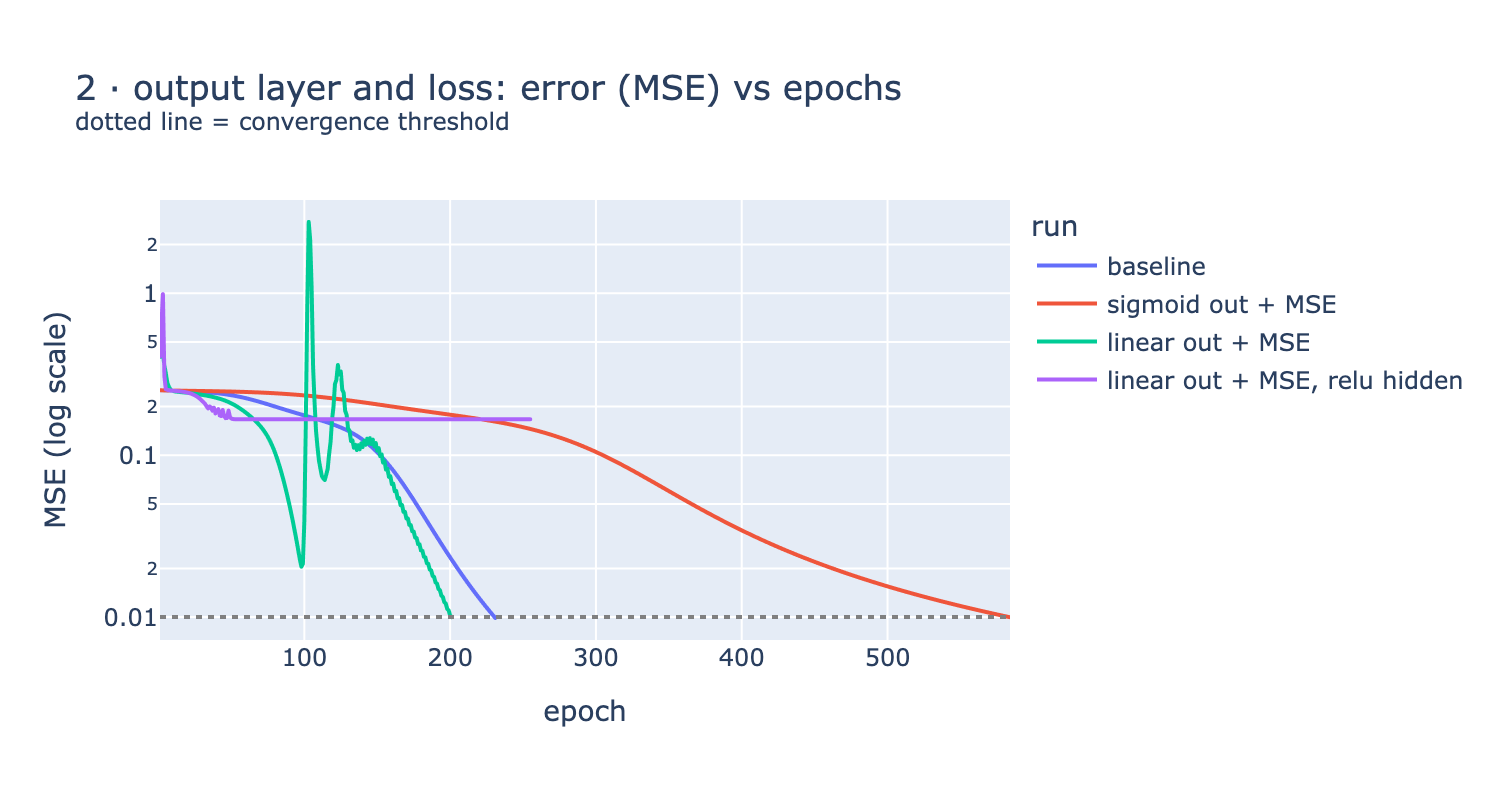

In [9]:

EXP2 = "2 · output layer and loss"
run(EXP2, "sigmoid out + MSE", loss="mean_squared_error")
run(EXP2, "linear out + MSE", activation_out="linear", loss="mean_squared_error")
run(EXP2, "linear out + MSE, relu hidden", activation_out="linear", loss="mean_squared_error", activation_h="relu")
show(EXP2)


**Results:**
* **Linear output + MSE** (hidden activation tanh) was the best option: it converged at epoch 201 (1.1× speed-up).
  A linear output doesn't saturate, so the output gradient is simply $\hat y - y$, as with sigmoid + BCE.
  The downside: the outputs are unbounded (it predicted 1.108 for a target of 1), so they need a threshold
  and can't be read as probabilities.
* **Sigmoid output + MSE** (only the loss changed) performed poorly: 584 epochs, 2.5× slower than the baseline.
  With BCE + sigmoid the output gradient is simply $\hat y - y$; with MSE it is multiplied by
  $\sigma'(z) \le 0.25$, which shrinks the updates.
* **Linear output + MSE with a ReLU hidden layer never converged** with this seed (stuck), most likely because of
  dead ReLU units (see Experiment 1).


## Experiment 3: changing the initialization

Only the initialization was modified, all other baseline configs stay the same.

* **zeros:** all neurons start identical. This is expected to fail (the symmetry problem).
* **random_normal** (σ = 0.05, small).
* **glorot_uniform** (Keras default).
* **he_normal** (designed for ReLU).
* **RandomNormal σ = 3:** deliberately too large, so tanh starts saturated.


init zeros                               stuck          epochs:     -  (2.6s)
init random_normal (σ=0.05)              stuck          epochs:     -  (2.7s)
init glorot_uniform                      converged      epochs:   199  (2.6s)
init he_normal                           converged      epochs:   210  (2.6s)
init RandomNormal σ=3                    not converged  epochs:     -  (23.2s)


,changes,epochs,status,final MSE,speedup
name,,,,,
baseline,-,231,converged,0.0099,1.0x
init zeros,init=zeros,<NA>,stuck,0.2500,-
init random_normal (σ=0.05),init=random_normal,<NA>,stuck,0.2500,-
init glorot_uniform,init=glorot_uniform,199,converged,0.0099,1.2x
init he_normal,init=he_normal,210,converged,0.0099,1.1x
init RandomNormal σ=3,"init={'class_name': 'RandomNormal', 'config': ...",<NA>,not converged,0.1253,-


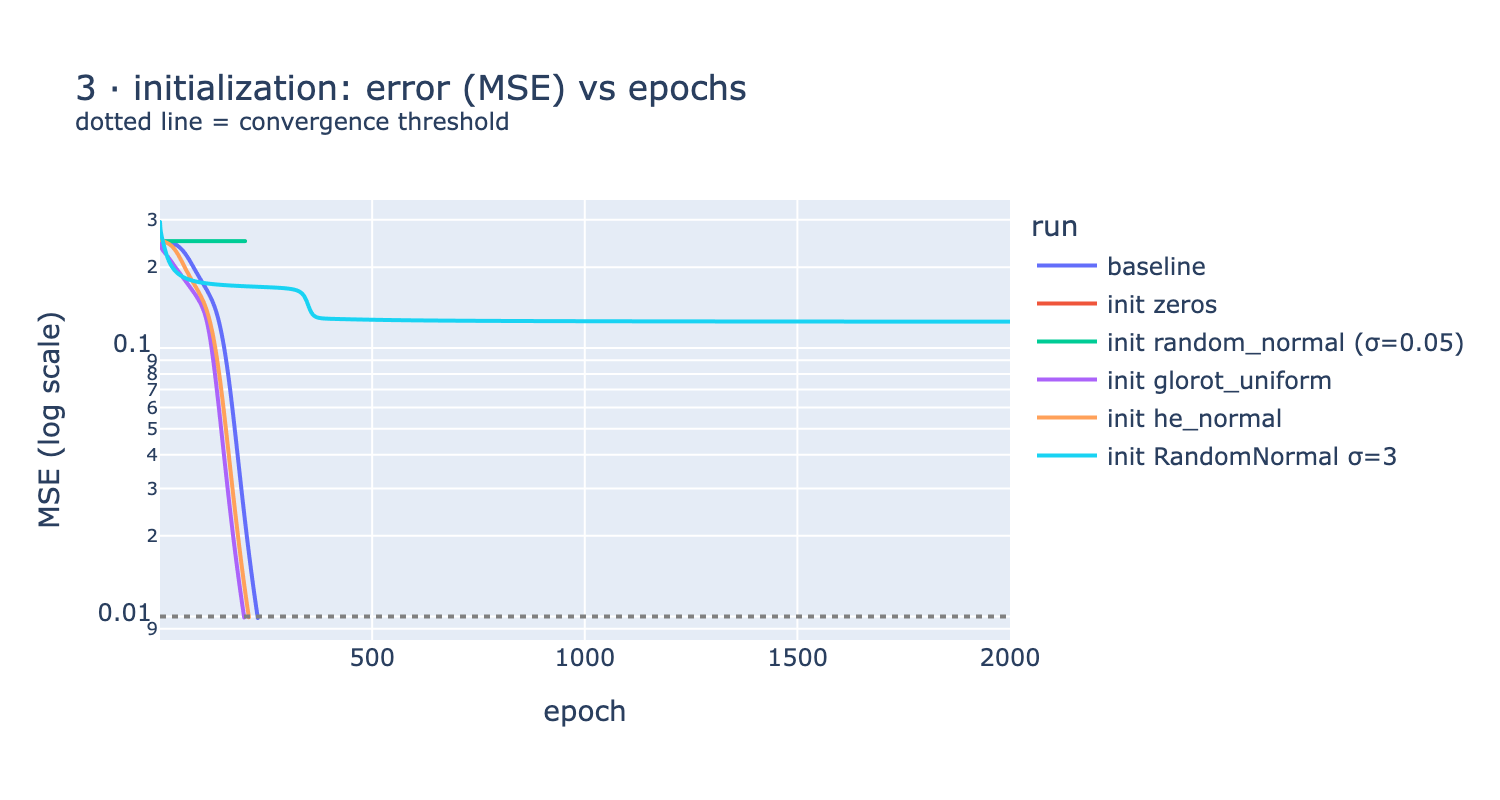

In [10]:

EXP3 = "3 · initialization"
run(EXP3, "init zeros", init="zeros")
run(EXP3, "init random_normal (σ=0.05)", init="random_normal")
run(EXP3, "init glorot_uniform", init="glorot_uniform")
run(EXP3, "init he_normal", init="he_normal")
run(EXP3, "init RandomNormal σ=3", init={"class_name": "RandomNormal", "config": {"stddev": 3.0}})
show(EXP3)


**Results:**
* **Zeros, small random normal (σ = 0.05) and large random normal (σ = 3) did not converge.**
  * *Zeros:* all neurons start identical, receive identical gradients and stay identical (the symmetry problem).
  * *σ = 0.05:* the weights are so small that the network starts almost symmetric, near a flat region, and plain
    SGD made no progress within the 200-epoch patience window (stuck at the same MSE = 0.25).
  * *σ = 3:* the weights are so large that the tanh neurons saturate: their outputs sit near ±1 and their gradients are almost zero, so learning stalls.
* **Glorot uniform (199 epochs) and He normal (210)** were slightly faster than the baseline's Glorot normal (231), but differences this small are within single-seed noise.
* **Takeaway:** initialization mostly decides **whether** the network learns at all. Among sensible, properly
  scaled random schemes, it barely changes **how fast** (up to 1.2x speed-up in this experiment).


## Experiment 4: changing the network topology

More neurons in the single hidden layer (3, 4, 8, 16), and also a **second hidden layer**. XOR does not *need* a second layer (one hidden layer with 2 neurons is enough in theory), but extra capacity can make the optimization easier and faster, so it's worth testing.


n_h=3                                    converged      epochs:  1883  (22.4s)
n_h=4                                    converged      epochs:   173  (2.2s)
n_h=8                                    converged      epochs:   154  (2.0s)
n_h=16                                   converged      epochs:   136  (1.8s)
2 hidden layers [4, 4]                   converged      epochs:   326  (4.2s)
2 hidden layers [8, 8]                   converged      epochs:    68  (1.0s)


,changes,epochs,status,final MSE,speedup
name,,,,,
baseline,-,231,converged,0.0099,1.0x
n_h=3,n_h=3,1883,converged,0.0096,0.1x
n_h=4,n_h=4,173,converged,0.0099,1.3x
n_h=8,n_h=8,154,converged,0.0098,1.5x
n_h=16,n_h=16,136,converged,0.0099,1.7x
"2 hidden layers [4, 4]","n_h=[4, 4]",326,converged,0.0099,0.7x
"2 hidden layers [8, 8]","n_h=[8, 8]",68,converged,0.0091,3.4x


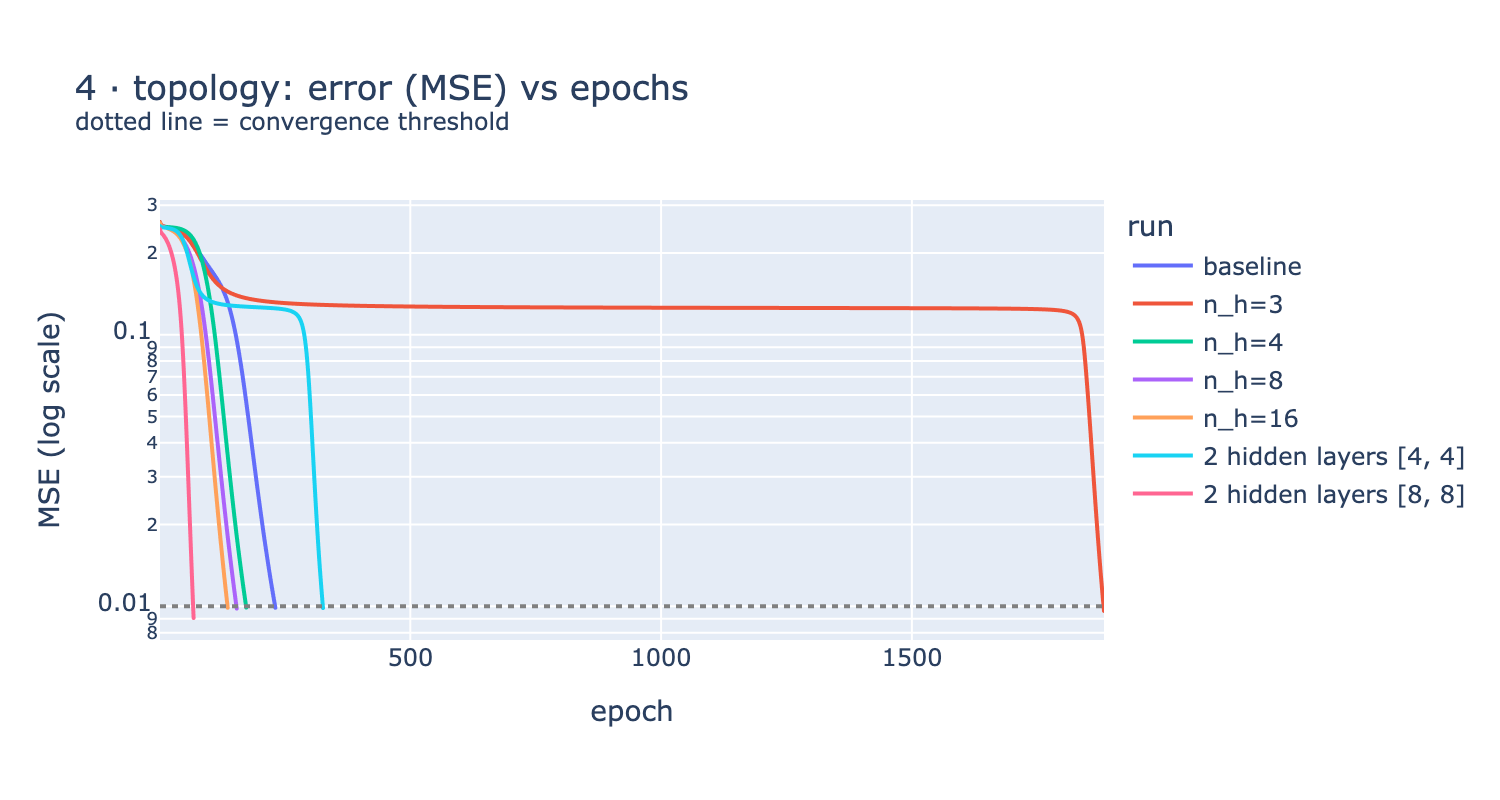

In [11]:

EXP4 = "4 · topology"
for n in [3, 4, 8, 16]:
    run(EXP4, f"n_h={n}", n_h=n)
for layers in [[4, 4], [8, 8]]:
    run(EXP4, f"2 hidden layers {layers}", n_h=layers)
show(EXP4)


**Results:**
* Increasing the neurons in the single hidden layer to **4, 8 and 16** had a positive effect: 173, 154 and
  136 epochs.
* Increasing to **3 neurons** had a negative impact: 1883 epochs, about 8× slower than the baseline, which may be a seed related unlucky effect.
* With a second hidden layer, **[4, 4]** was slower than the baseline (326 epochs, 0.7× speed-up), while
  **[8, 8]** was the best topology (68 epochs, 3.4× speed-up). XOR doesn't *need* the second layer, but the extra capacity makes the optimization easier, which points to a possible benefit of using larger models.
* Since the trend is not completely clear (3 neurons and [4, 4]), it might be a bad luck from the seed (a network can start near a plateau) so individual runs like these shouldn't be over-interpreted.


## Experiment 5 (additional): optimizer and learning rate

Not listed explicitly in the assignment, but the optimizer and learning rate decide the size of each weight update, so they have a direct effect on the number of epochs.


SGD lr=0.1                               converged      epochs:  1144  (14.8s)
SGD lr=1.0                               converged      epochs:   117  (1.7s)
SGD lr=2.0                               converged      epochs:    62  (1.0s)
SGD lr=0.5 + momentum 0.9                converged      epochs:    44  (0.9s)
Adam lr=0.05                             converged      epochs:    62  (1.2s)
Adam lr=0.1                              converged      epochs:    39  (1.0s)


,changes,epochs,status,final MSE,speedup
name,,,,,
baseline,-,231,converged,0.0099,1.0x
SGD lr=0.1,lr=0.1,1144,converged,0.0100,0.2x
SGD lr=1.0,lr=1.0,117,converged,0.0097,2.0x
SGD lr=2.0,lr=2.0,62,converged,0.0099,3.7x
SGD lr=0.5 + momentum 0.9,momentum=0.9,44,converged,0.0088,5.2x
Adam lr=0.05,"optimizer=adam, lr=0.05",62,converged,0.0099,3.7x
Adam lr=0.1,"optimizer=adam, lr=0.1",39,converged,0.0078,5.9x


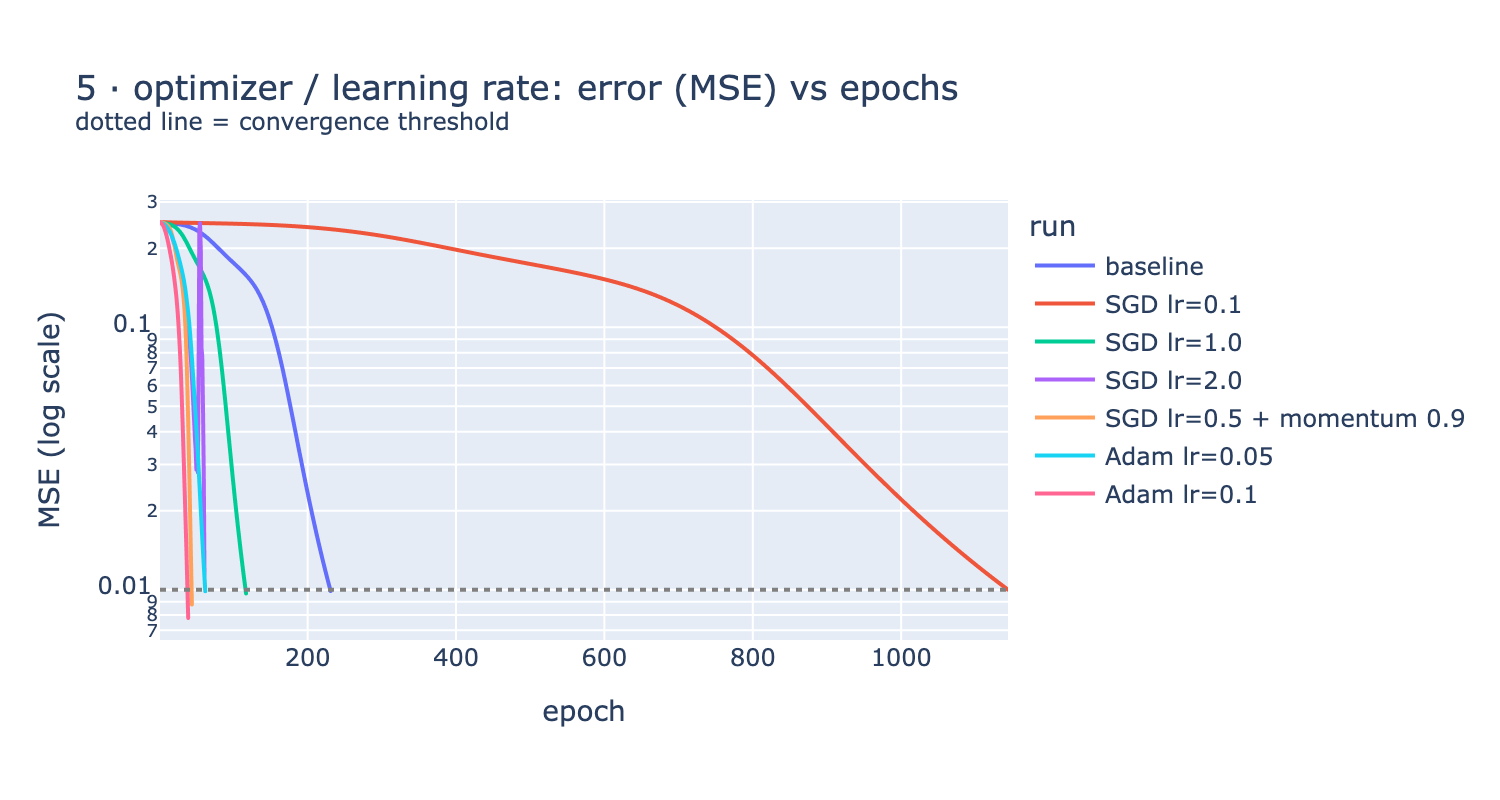

In [12]:

EXP5 = "5 · optimizer / learning rate"
for lr in [0.1, 1.0, 2.0]:
    run(EXP5, f"SGD lr={lr}", lr=lr)
run(EXP5, "SGD lr=0.5 + momentum 0.9", momentum=0.9)
for lr in [0.05, 0.1]:
    run(EXP5, f"Adam lr={lr}", optimizer="adam", lr=lr)
show(EXP5)


**Results:** the baseline used SGD with a learning rate of 0.5. The optimizer and learning rate turned out to be
the strongest single setting:
* With plain SGD the epochs scale roughly inversely with the learning rate: lr 0.1 → 1144 epochs (0.2× speed-up),
  0.5 → 231, 1.0 → 117, 2.0 → 62.
* Adding **momentum 0.9** (lr 0.5) was the best SGD variant: 44 epochs (5.2× speed-up).
* Switching to **Adam** was even faster: 62 epochs with lr = 0.05 and 39 with lr = 0.1 (5.9× speed-up).


## Experiment 6: combining the best options (cumulative)

Starting from the baseline, each step tests a group of options **on top of the current best configuration** and keeps the winner (fewest epochs; ties broken by the lower final MSE). The current configuration is kept if no option beats it.

Order: topology → hidden activation → initialization → output/loss → optimizer/learning rate.


In [13]:

EXP6 = "6 · combined"

search_steps = {
    "topology":   {f"n_h={n}": dict(n_h=n) for n in [2, 4, 8, 16, [4, 4], [8, 8], [16, 16]]},
    "activation": {f"hidden {a}": dict(activation_h=a) for a in ["tanh", "sigmoid", "relu", "leaky_relu", "elu"]},
    "init":       {f"init {i}": dict(init=i) for i in ["glorot_normal", "glorot_uniform", "he_normal", "he_uniform"]},
    "output":     {"sigmoid + BCE": dict(activation_out="sigmoid", loss="binary_crossentropy"),
                   "sigmoid + MSE": dict(activation_out="sigmoid", loss="mean_squared_error"),
                   "linear + MSE":  dict(activation_out="linear", loss="mean_squared_error")},
    "optimizer":  {"SGD lr=0.5": dict(optimizer="sgd", lr=0.5, momentum=0.0),
                   "SGD lr=1.0": dict(optimizer="sgd", lr=1.0, momentum=0.0),
                   "SGD lr=0.5 + momentum": dict(optimizer="sgd", lr=0.5, momentum=0.9),
                   "Adam lr=0.05": dict(optimizer="adam", lr=0.05),
                   "Adam lr=0.1": dict(optimizer="adam", lr=0.1),
                   "Adam lr=0.2": dict(optimizer="adam", lr=0.2)},
}

def score(r):   # fewer epochs is better; non-converged runs rank last
    return (r["epochs_to_converge"] or float("inf"), r["final_mse"])

current = {}            # changes accumulated on top of base_config
best_steps = []
for step, options in search_steps.items():
    print(f"\n--- step: {step} ---")
    step_runs = [run(EXP6, f"[{step}] {label}", **{**current, **changes})
                 for label, changes in options.items()]
    best = min(step_runs, key=score)
    current = {k: v for k, v in best["config"].items() if base_config.get(k) != v}
    best_steps.append(best)
    print(f"=> keep {best['name']}  ({best['epochs_to_converge']} epochs)")

print("\nFinal configuration (changes from the baseline):", current)



--- step: topology ---
[topology] n_h=2                         converged      epochs:   231  (2.9s)
[topology] n_h=4                         converged      epochs:   173  (2.3s)
[topology] n_h=8                         converged      epochs:   154  (2.0s)
[topology] n_h=16                        converged      epochs:   136  (1.9s)
[topology] n_h=[4, 4]                    converged      epochs:   326  (4.0s)
[topology] n_h=[8, 8]                    converged      epochs:    68  (1.1s)
[topology] n_h=[16, 16]                  converged      epochs:    73  (1.1s)
=> keep [topology] n_h=[8, 8]  (68 epochs)

--- step: activation ---
[activation] hidden tanh                 converged      epochs:    68  (1.1s)
[activation] hidden sigmoid              converged      epochs:  1066  (13.1s)
[activation] hidden relu                 converged      epochs:    38  (0.6s)
[activation] hidden leaky_relu           converged      epochs:    47  (0.8s)
[activation] hidden elu                  converg

In this experiment the options were combined **cumulatively**. Starting from the baseline, each group of
options (topology → hidden activation → initialization → output/loss → optimizer) was re-tested **on top of
the best configuration found so far**, and the option with the fewest epochs was kept.
Since the choices can interact with one another, this is different from simply stacking the individual
winners of experiments 1–5.

**Final configuration** (changes from the baseline):

* two hidden layers with 8 neurons each (`n_h = [8, 8]`)
* ReLU hidden activation
* He normal initialization
* Adam optimizer, learning rate 0.2
* (kept from the baseline: sigmoid output + binary cross-entropy)

**Progress:** 231 → 68 (two layers [8, 8]) → 38 (ReLU) → 29 (He normal) → 29 (sigmoid + BCE kept) →
**10 epochs** (Adam, lr = 0.2), a 23× speed-up over the baseline. The final network predicts
[0.020, 0.021, 0.994, 0.997] (MSE 0.0014): it doesn't just reach the threshold, it goes well past it.

Some patterns from this experiment:

* **ReLU seems to benefit from a larger network.** With only 2 hidden neurons, ReLU was barely faster than tanh
  (185 vs 231 epochs) and got stuck in another setup. With two layers of 8 neurons it almost halved
  the epochs (68 → 38): with many neurons, losing a few "dead" ones no longer matters. This is consistent
  with ReLU being the default in today's deeper architectures.
* **He normal initialization gave a further gain** with ReLU (38 → 29), consistent with it being designed
  for ReLU. With a single seed this isn't conclusive, though. He uniform, also designed for ReLU, was
  the slowest option in that step (49).
* **Adam gave the largest improvement** (29 → 10 epochs). As an adaptive optimizer it scales each weight's
  update individually, which allows large, stable steps. It's also the most widely used optimizer today.
* **Sigmoid output + BCE was kept:** This is consistent with BCE + sigmoid being the standard choice for binary classification.

,changes,epochs,status,final MSE,speedup
name,,,,,
"[topology] n_h=[8, 8]","n_h=[8, 8]",68,converged,0.0091,3.4x
[activation] hidden relu,"n_h=[8, 8], activation_h=relu",38,converged,0.0100,6.1x
[init] init he_normal,"n_h=[8, 8], activation_h=relu, init=he_normal",29,converged,0.0095,8.0x
[output] sigmoid + BCE,"n_h=[8, 8], activation_h=relu, init=he_normal,...",29,converged,0.0095,8.0x
[optimizer] Adam lr=0.2,"n_h=[8, 8], activation_h=relu, init=he_normal,...",10,converged,0.0014,23.1x


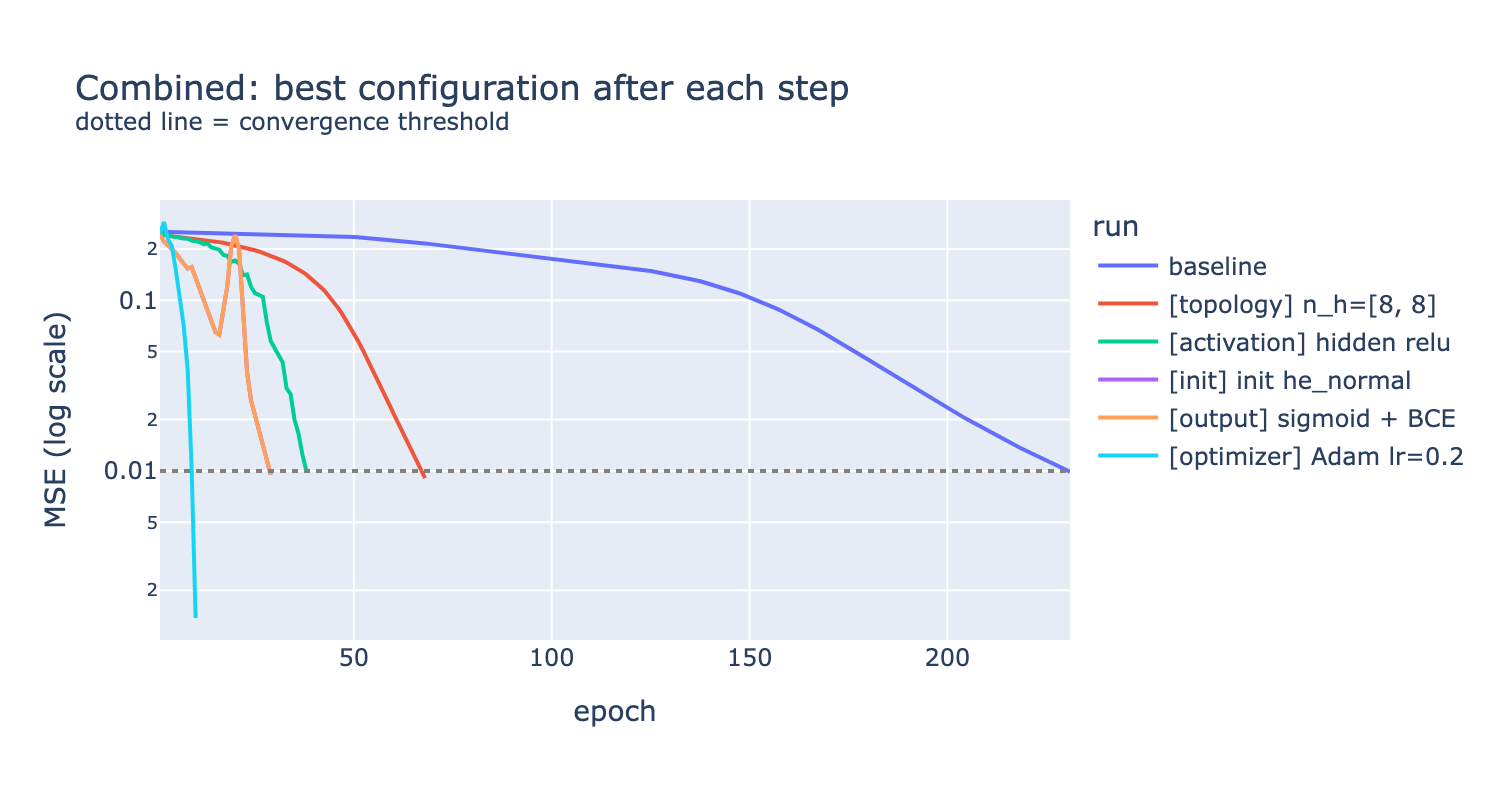

In [14]:

progress = summary_table(best_steps).set_index("name")[["changes", "epochs_to_converge", "status",
                                                        "final_mse", "speedup_vs_baseline"]]
display(table(progress))
plot_curves([r for r in RUNS if r["experiment"] == "baseline"] + best_steps,
            "Combined: best configuration after each step")


Another interesting remark from this figure: with Adam the error drops smoothly and fast, while the SGD + ReLU curves show bumps.


# Final comparison

The baseline, the best run of each one-at-a-time experiment, and the final combined configuration.


,experiment,epochs,status,final MSE,speedup
name,,,,,
baseline,baseline,231,converged,0.0099,1.0x
hidden relu,1 · hidden activation,185,converged,0.0099,1.2x
linear out + MSE,2 · output layer and loss,201,converged,0.0100,1.1x
init glorot_uniform,3 · initialization,199,converged,0.0099,1.2x
"2 hidden layers [8, 8]",4 · topology,68,converged,0.0091,3.4x
Adam lr=0.1,5 · optimizer / learning rate,39,converged,0.0078,5.9x
[optimizer] Adam lr=0.2,6 · combined,10,converged,0.0014,23.1x


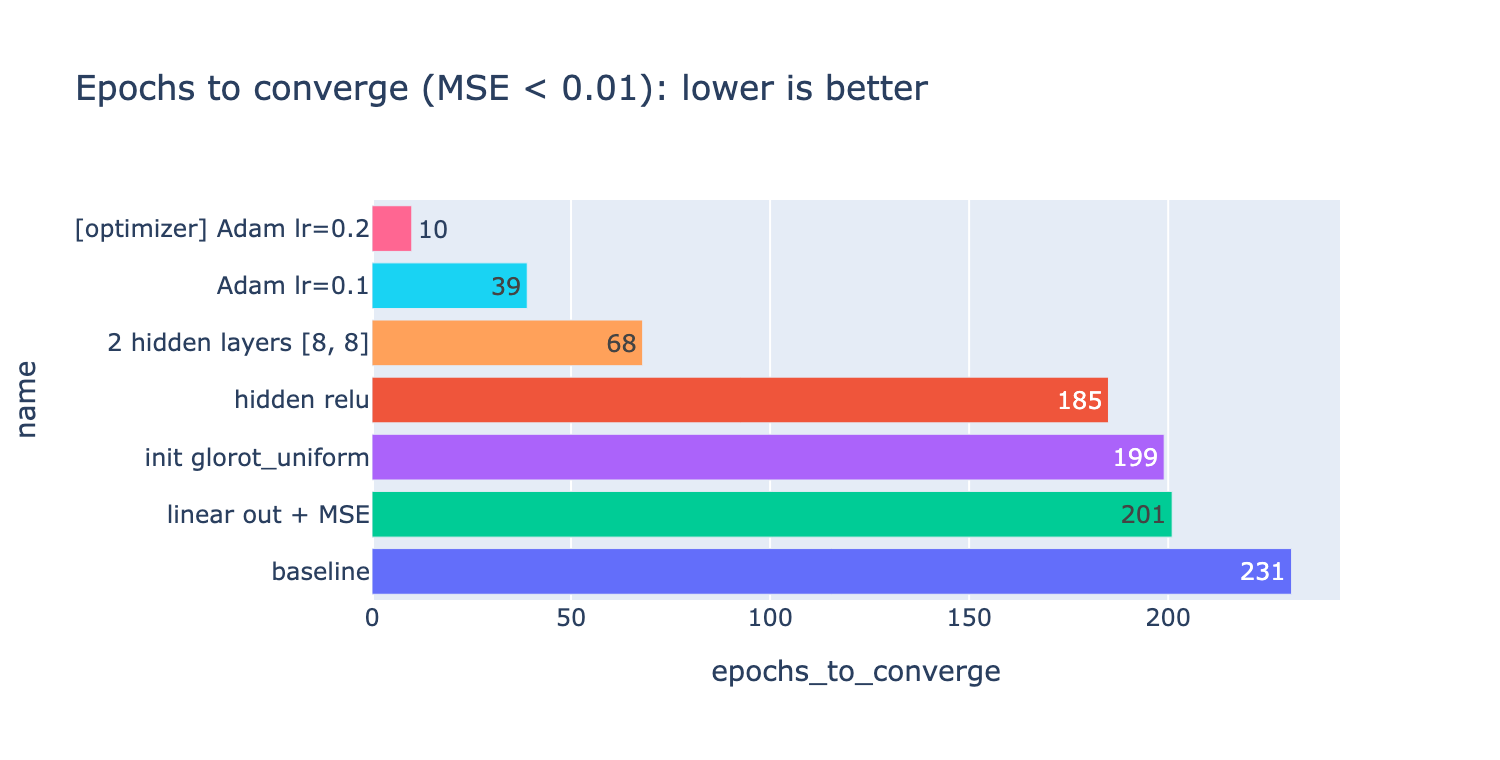

In [15]:

finalists = [next(r for r in RUNS if r["experiment"] == "baseline")]
for exp in [EXP1, EXP2, EXP3, EXP4, EXP5]:
    finalists.append(min([r for r in RUNS if r["experiment"] == exp], key=score))
finalists.append(best_steps[-1])

final_table = summary_table(finalists).set_index("name")[
    ["experiment", "changes", "epochs_to_converge", "status", "final_mse", "speedup_vs_baseline", "predictions"]]
final_table.to_csv(f"{RESULTS_DIR}/final_comparison.csv")
display(table(final_table, hide=["changes"]))

bars = final_table.reset_index().astype({"epochs_to_converge": "float"})
fig = px.bar(bars, x="epochs_to_converge", y="name", orientation="h",
             color="experiment", width=750, height=380, text="epochs_to_converge",
             title="Epochs to converge (MSE < 0.01): lower is better")
fig.update_layout(yaxis=dict(categoryorder="total descending"), showlegend=False)
fig.show()


In [16]:

# Full table of every run (also saved in results/summary.csv)
pd.set_option("display.max_rows", 200)
table(summary_table(RUNS).drop(columns=["predictions"]).set_index(["experiment", "name"]), hide=["changes"])


epochs  \
experiment                    name                                        
baseline                      baseline                              231   
1 · hidden activation         hidden sigmoid                       1540   
                              hidden relu                           185   
                              hidden leaky_relu                     308   
                              hidden elu                           <NA>   
2 · output layer and loss     sigmoid out + MSE                     584   
                              linear out + MSE                      201   
                              linear out + MSE, relu hidden        <NA>   
3 · initialization            init zeros                           <NA>   
                              init random_normal (σ=0.05)          <NA>   
                              init glorot_uniform                   199   
                              init he_normal                        210   
                              init RandomNormal σ=3                <NA>   
4 · topology                  n_h=3                                1883   
                              n_h=4                                 173   
                              n_h=8                                 154   
                              n_h=16                                136   
                              2 hidden layers [4, 4]                326   
                              2 hidden layers [8, 8]                 68   
5 · optimizer / learning rate SGD lr=0.1                           1144   
                              SGD lr=1.0                            117   
                              SGD lr=2.0                             62   
                              SGD lr=0.5 + momentum 0.9              44   
                              Adam lr=0.05                           62   
                              Adam lr=0.1                            39   
6 · combined                  [topology] n_h=2                      231   
                              [topology] n_h=4                      173   
                              [topology] n_h=8                      154   
                              [topology] n_h=16                     136   
                              [topology] n_h=[4, 4]                 326   
                              [topology] n_h=[8, 8]                  68   
                              [topology] n_h=[16, 16]                73   
                              [activation] hidden tanh               68   
                              [activation] hidden sigmoid          1066   
                              [activation] hidden relu               38   
                              [activation] hidden leaky_relu         47   
                              [activation] hidden elu                62   
                              [init] init glorot_normal              38   
                              [init] init glorot_uniform             32   
                              [init] init he_normal                  29   
                              [init] init he_uniform                 49   
                              [output] sigmoid + BCE                 29   
                              [output] sigmoid + MSE                 66   
                              [output] linear + MSE                <NA>   
                              [optimizer] SGD lr=0.5                 29   
                              [optimizer] SGD lr=1.0                 19   
                              [optimizer] SGD lr=0.5 + momentum      11   
                              [optimizer] Adam lr=0.05               16   
                              [optimizer] Adam lr=0.1                12   
                              [optimizer] Adam lr=0.2                10   

                                                                        status  \
experiment                    name                                               



# Analysis

All results use seed 3. **Converged** = MSE < 0.01. The baseline is 2-2-1, tanh, Glorot normal, sigmoid + BCE, SGD lr = 0.5, and it needs **231 epochs**.

```
base_config = dict(
    # hyperparameters
    lr = 0.5,
    optimizer = "sgd",      # "sgd" or "adam"
    momentum = 0.0,         # only used by SGD
    epochs = 2000,          # upper limit; training stops earlier once converged
    batch_size = len(x),    # full batch: 1 epoch = 1 weight update
    seed = 3,
    patience = 200,         # stop a stuck run after 200 epochs without improvement
    # model
    n_h = 2,                # int = one hidden layer with n_h neurons; list, e.g. [8, 8] = several hidden layers
    activation_h = "tanh",
    activation_out = "sigmoid",
    init = "glorot_normal", # https://keras.io/api/layers/initializers/
    loss = "binary_crossentropy",
)

```

### Summary

| Experiment | Best option | Epochs | vs baseline |
|---|---|---|---|
| baseline | 2-2-1, tanh, Glorot normal, sigmoid + BCE, SGD 0.5 | 231 | 1.0× |
| 1 · hidden activation | ReLU | 185 | 1.2× |
| 2 · output layer and loss | linear output + MSE | 201 | 1.1× |
| 3 · initialization | Glorot uniform | 199 | 1.2× |
| 4 · topology | 2 hidden layers [8, 8] | 68 | 3.4× |
| 5 · optimizer / learning rate | Adam lr = 0.1 | 39 | 5.9× |
| **6 · combined** | **2-8-8-1, ReLU, He normal, sigmoid + BCE, Adam 0.2** | **10** | **23×** |

By experimenting with the hyperparameters and the topology of the network, it was possible to converge
**23× faster** than the baseline (231 → 10 epochs).

* **Most of the gains came from the topology** (up to 3.4×, two hidden layers of 8) **and the optimizer /
  learning rate** (up to 5.9×, Adam), and they add up: combined with ReLU and He initialization, the final
  network converged in 10 epochs.
* **Changes to the hidden activation, the output/loss and the initialization gave at most a 1.2× speed-up on
  their own.** Their bigger effect was negative: bad choices (sigmoid hidden layer, MSE with a sigmoid output,
  zeros or badly scaled initialization) made training much slower or stopped it completely.
* **The choices interact.** ReLU barely helped in the minimal 2-2-1 network, but nearly halved the epochs in the
  [8, 8] network (Experiment 6). Testing each option on top of the current best, instead of stacking the
  individual winners, captures this.

### Which options lead to fewer epochs? (assignment item 6)
1. **A larger effective step:** a higher learning rate, momentum, or an adaptive optimizer (Adam), had the biggest effect.
2. **More capacity than the theoretical minimum:** wider and especially deeper (two hidden layers). The minimal 2-2-1 network trains slowly.
3. **Non-saturating activations:** tanh or ReLU instead of sigmoid in the hidden layer. ReLU only pays off with enough neurons (and He initialization).
4. **A sigmoid output with binary cross-entropy** instead of MSE, because BCE avoids the shrinking $\sigma'$ factor. (A linear output + MSE might be comparable in speed, but its outputs aren't probabilities.)
5. **Properly scaled random initialization** (Glorot / He). Zeros, too small or too large can stop learning completely.

### Limitations
* **One seed.** Results like n_h = 3 (1883 epochs) show that a single run can be unlucky, we would need other seeds to be sure about the effects. The large effects (learning rate / optimizer, depth, sigmoid making the training slow as hidden activation, zero initialization failing) agree with theory and are reliable. Small differences, such as 199 vs 231 epochs, aren't meaningful. Repeating every configuration with several seeds and reporting the median would make the conclusions stronger.
* **Epochs are not compute.** The final 2-8-8-1 network has 105 parameters versus 9 for the baseline, so each epoch costs more. For XOR both are negligible.
* **The numbers depend on the threshold** (MSE < 0.01) and on "stuck" meaning *no progress for 200 epochs*. A stuck run might still escape much later.
